In [2]:
%matplotlib widget
import xarray as xr
import numpy as np
import dask.array as da
import h5py
import os
import matplotlib.pyplot as plt
from scipy import signal as sp_signal

In [3]:
# Verified physical on-disk ground-truth ordering (classes-fixed)
CLASSES_FIXED = np.array(
    [
        "OOK",
        "4ASK",
        "8ASK",
        "BPSK",
        "QPSK",
        "8PSK",
        "16PSK",
        "32PSK",
        "16APSK",
        "32APSK",
        "64APSK",
        "128APSK",
        "16QAM",
        "32QAM",
        "64QAM",
        "128QAM",
        "256QAM",
        "AM-SSB-WC",
        "AM-SSB-SC",
        "AM-DSB-WC",
        "AM-DSB-SC",
        "FM",
        "GMSK",
        "OQPSK",
    ]
)

H5_PATH = os.path.join("radioml2018", "GOLD_XYZ_OSC.0001_1024.hdf5")

# 1. Open lazily using the h5netcdf backend to avoid loading the 20GB into RAM
ds_raw = xr.open_dataset(
    H5_PATH,
    engine="h5netcdf",
    phony_dims="access",
    chunks={"phony_dim_0": 10000},  # Chunk size along sample axis
)

# 2. Rename datasets and auto-generated phony dimensions
ds = ds_raw.rename(
    {
        "X": "signal",
        "Y": "modulation_onehot",
        "Z": "snr_raw",
        "phony_dim_0": "sample",
        "phony_dim_1": "time",
        "phony_dim_2": "channel",
        "phony_dim_3": "class_idx",
    }
)

# 3. Pull 1D metadata vectors into memory (only ~5MB RAM total for 2.55M rows)
mod_indices = ds["modulation_onehot"].argmax(dim="class_idx").values
snr_values = ds["snr_raw"].squeeze().values.astype(np.int16)

# 4. Attach labeled coordinates and drop redundant intermediate dims
ds = ds.assign_coords(
    {
        "channel": ["I", "Q"],
        "modulation": ("sample", CLASSES_FIXED[mod_indices]),
        "snr": ("sample", snr_values),
        "time": np.arange(1024),
    }
).drop_vars([ "snr_raw", "modulation_onehot"])

In [4]:
sig = ds["signal"].sel(modulation="128APSK").sel(snr=0).isel(sample=0)

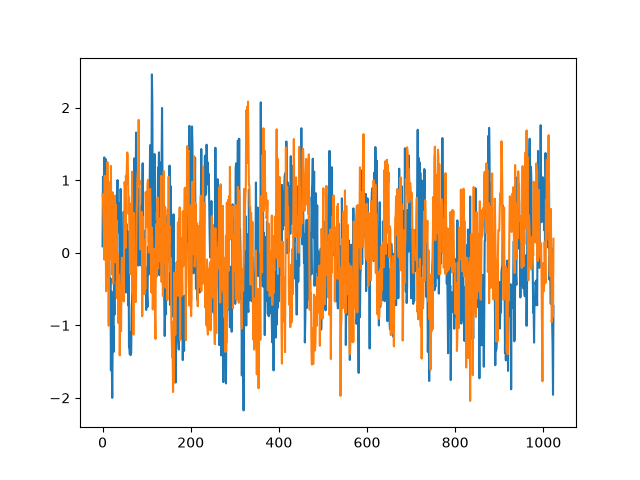

In [5]:
plt.plot(sig)

In [6]:
vals = sig.values

if vals.shape[0] == 2:
    i_data, q_data = vals[0, :], vals[1, :]
else:
    i_data, q_data = vals[:, 0], vals[:, 1]

complex_iq = i_data + 1j * q_data
n_samples = len(i_data)
time_idx = np.arange(n_samples)

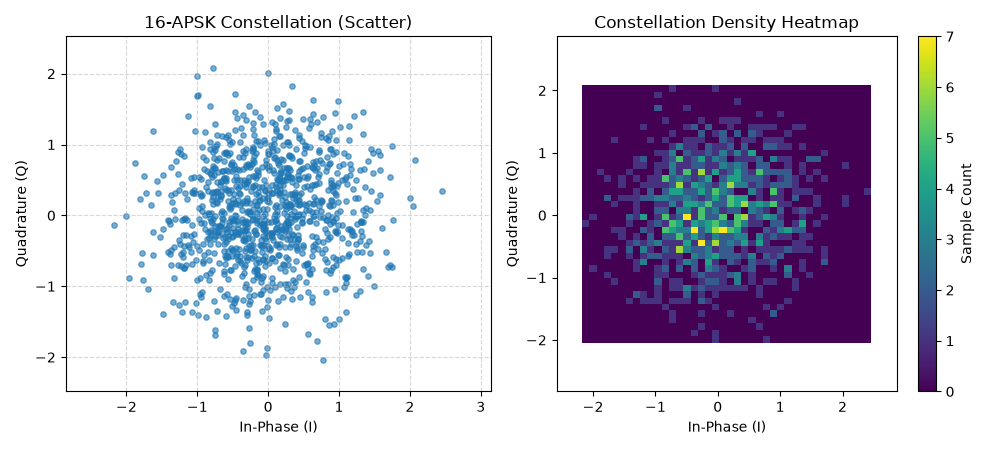

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Scatter plot
axes[0].scatter(i_data, q_data, alpha=0.6, s=15, color="tab:blue")
axes[0].set_title("16-APSK Constellation (Scatter)")
axes[0].set_xlabel("In-Phase (I)")
axes[0].set_ylabel("Quadrature (Q)")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].axis("equal")

# 2D Histogram / Density
h = axes[1].hist2d(i_data, q_data, bins=40, cmap="viridis")
fig.colorbar(h[3], ax=axes[1], label="Sample Count")
axes[1].set_title("Constellation Density Heatmap")
axes[1].set_xlabel("In-Phase (I)")
axes[1].set_ylabel("Quadrature (Q)")
axes[1].axis("equal")

plt.tight_layout()
plt.show()

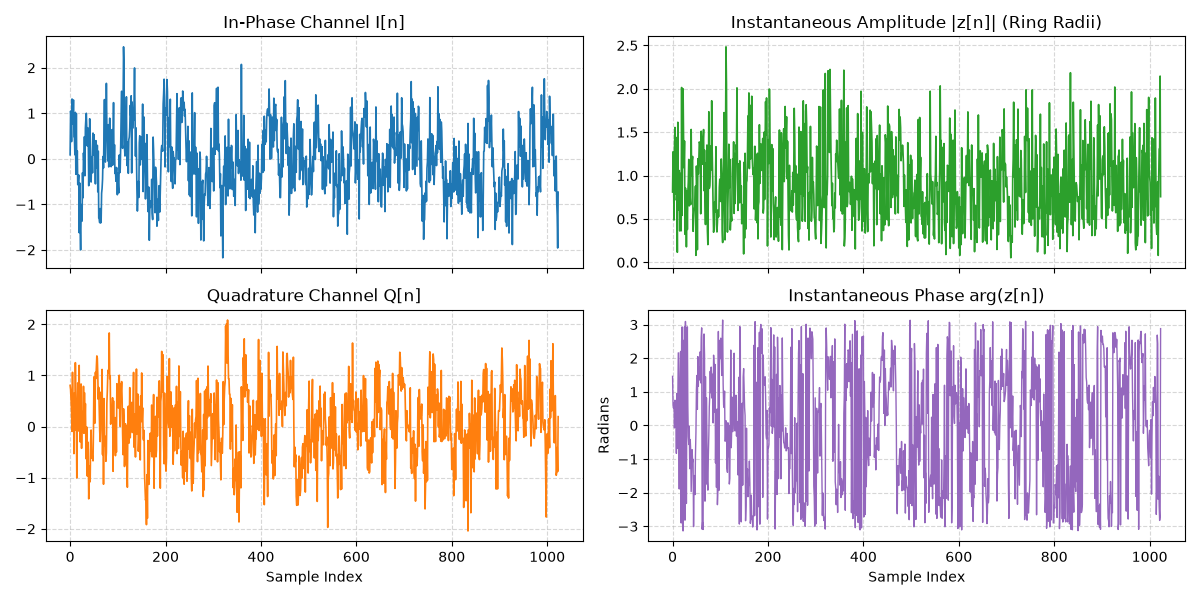

In [8]:
# Convert to Polar
amplitude = np.abs(complex_iq)
phase = np.angle(complex_iq)  # Radians (-pi to pi)

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)

# I and Q time series
axes[0, 0].plot(time_idx, i_data, color="tab:blue", lw=1.2)
axes[0, 0].set_title("In-Phase Channel I[n]")
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

axes[1, 0].plot(time_idx, q_data, color="tab:orange", lw=1.2)
axes[1, 0].set_title("Quadrature Channel Q[n]")
axes[1, 0].set_xlabel("Sample Index")
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

# Polar: Amplitude and Phase
axes[0, 1].plot(time_idx, amplitude, color="tab:green", lw=1.2)
axes[0, 1].set_title("Instantaneous Amplitude |z[n]| (Ring Radii)")
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

axes[1, 1].plot(time_idx, phase, color="tab:purple", lw=1.0)
axes[1, 1].set_title("Instantaneous Phase arg(z[n])")
axes[1, 1].set_xlabel("Sample Index")
axes[1, 1].set_ylabel("Radians")
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

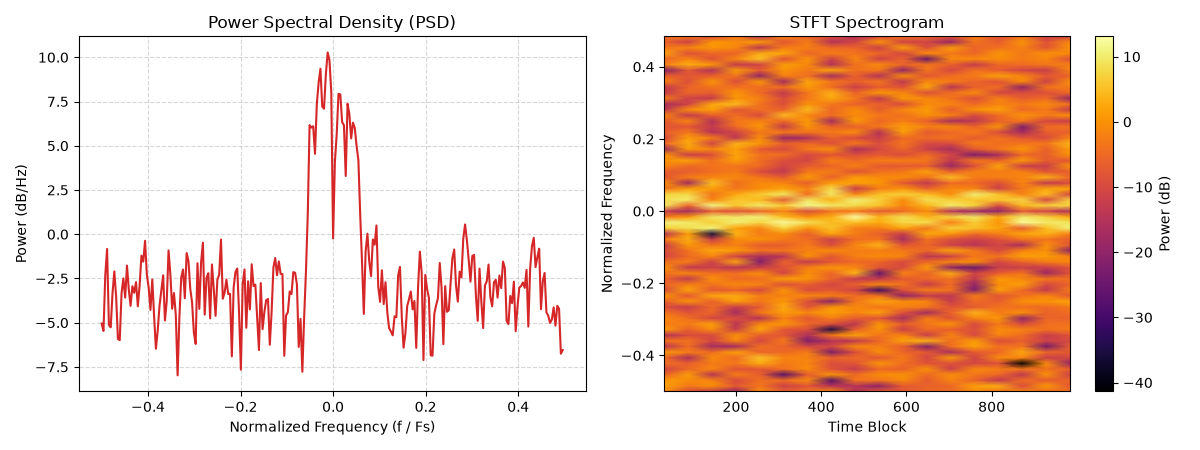

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Power Spectral Density (Welch Periodogram)
freqs, psd = sp_signal.welch(
    complex_iq, fs=1.0, return_onesided=False, scaling="density"
)
freqs = np.fft.fftshift(freqs)
psd = np.fft.fftshift(psd)

axes[0].plot(freqs, 10 * np.log10(psd + 1e-12), color="tab:red")
axes[0].set_title("Power Spectral Density (PSD)")
axes[0].set_xlabel("Normalized Frequency (f / Fs)")
axes[0].set_ylabel("Power (dB/Hz)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Spectrogram (STFT)
f, t, Sxx = sp_signal.spectrogram(
    complex_iq, fs=1.0, return_onesided=False, nperseg=min(64, n_samples // 4)
)
f = np.fft.fftshift(f)
Sxx = np.fft.fftshift(Sxx, axes=0)

im = axes[1].pcolormesh(
    t, f, 10 * np.log10(Sxx + 1e-12), cmap="inferno", shading="gouraud"
)
fig.colorbar(im, ax=axes[1], label="Power (dB)")
axes[1].set_title("STFT Spectrogram")
axes[1].set_xlabel("Time Block")
axes[1].set_ylabel("Normalized Frequency")

plt.tight_layout()
plt.show()

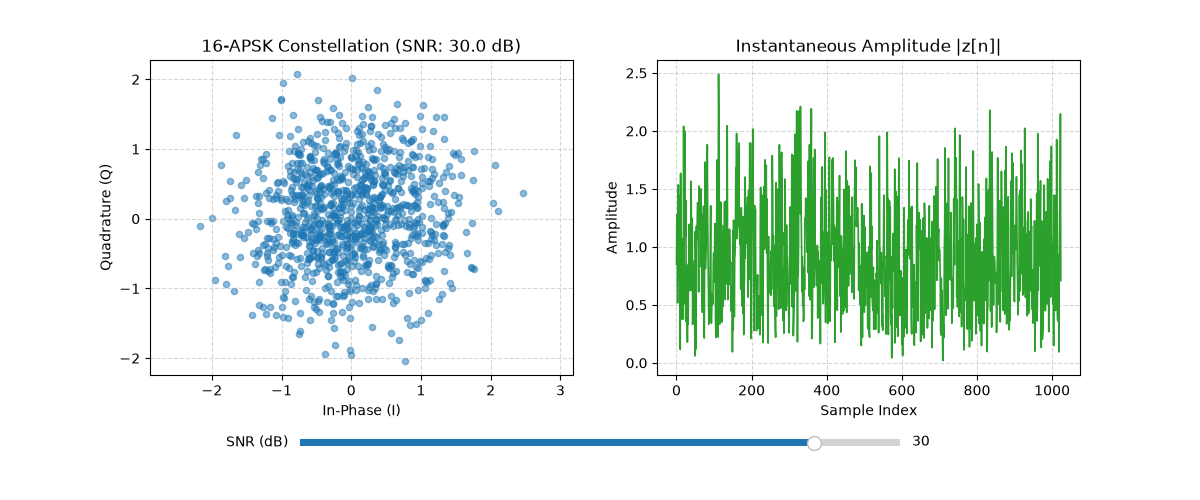

In [10]:
from matplotlib.widgets import Slider

# Extract clean baseband data
vals = sig.values
if vals.shape[0] == 2:
    i_raw, q_raw = vals[0, :], vals[1, :]
else:
    i_raw, q_raw = vals[:, 0], vals[:, 1]

clean_iq = i_raw + 1j * q_raw
sig_power = np.mean(np.abs(clean_iq) ** 2)
n_pts = len(clean_iq)

# Setup pre-generated unit Gaussian noise
np.random.seed(42)
noise_base = (np.random.randn(n_pts) + 1j * np.random.randn(n_pts)) / np.sqrt(2)


def compute_noisy(snr_db):
    snr_linear = 10.0 ** (snr_db / 10.0)
    noise_power = sig_power / snr_linear
    return clean_iq + np.sqrt(noise_power) * noise_base


# Initial plot state
initial_snr = 30.0
noisy_iq = compute_noisy(initial_snr)

fig = plt.figure(figsize=(12, 5))
plt.subplots_adjust(bottom=0.25)

# 1. Constellation Plot
ax_const = fig.add_subplot(1, 2, 1)
scat = ax_const.scatter(noisy_iq.real, noisy_iq.imag, alpha=0.5, s=20, color="tab:blue")
ax_const.set_title(f"16-APSK Constellation (SNR: {initial_snr:.1f} dB)")
ax_const.set_xlabel("In-Phase (I)")
ax_const.set_ylabel("Quadrature (Q)")
ax_const.grid(True, linestyle="--", alpha=0.5)
ax_const.axis("equal")

# 2. Instantaneous Amplitude (Ring Radii)
ax_amp = fig.add_subplot(1, 2, 2)
(amp_line,) = ax_amp.plot(np.abs(noisy_iq), color="tab:green", lw=1.2)
ax_amp.set_title("Instantaneous Amplitude |z[n]|")
ax_amp.set_xlabel("Sample Index")
ax_amp.set_ylabel("Amplitude")
ax_amp.grid(True, linestyle="--", alpha=0.5)

# Slider configuration
ax_slider = plt.axes([0.25, 0.1, 0.5, 0.03])
snr_slider = Slider(
    ax_slider, "SNR (dB)", valmin=0.0, valmax=35.0, valinit=initial_snr, valstep=0.5
)


def update(val):
    current_snr = snr_slider.val
    current_noisy = compute_noisy(current_snr)

    # Update scatter offsets and amplitude line
    scat.set_offsets(np.column_stack([current_noisy.real, current_noisy.imag]))
    amp_line.set_ydata(np.abs(current_noisy))
    ax_amp.set_ylim(0, np.max(np.abs(current_noisy)) * 1.1)
    ax_const.set_title(f"16-APSK Constellation (SNR: {current_snr:.1f} dB)")
    fig.canvas.draw_idle()


snr_slider.on_changed(update)
plt.show()